# Answers: visualising data 2 — what does one data point show?

Now you'll do the same with a new dataset, about what happens to reaction times when people don't get enough sleep.

**The study.** Belenky et al. (2003) restricted volunteers to **3 hours in bed per night** for a series of nights.
Every day they did reaction-time tests. The data are from the 18 people in the most sleep-restricted group.
According to the documentation of the R package the data come from (lme4), days 0 and 1 were adaptation and training,
**day 2 was the baseline**, and sleep restriction began after day 2.

Throughout, keep asking: **what does one point on my graph represent?**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks", context="notebook")

sleep_df = pd.read_csv("data/sleepstudy_belenky2003.csv")
sleep_df.head()

,Subject,Days,Reaction
0,308,0,249.5600
1,308,1,258.7047
2,308,2,250.8006
3,308,3,321.4398
4,308,4,356.8519


## 1. What does one row show?

Find out how many rows, participants (`Subject`) and days there are, and how many rows each participant has.
Then answer in words: **what does one row represent?** `Reaction` is in milliseconds. Is it a single trial?
Which step of the lecture ladder does this dataset *start* at?

In [2]:
# Number of rows, participants and days.
print("Rows:", len(sleep_df))
print("Participants:", sleep_df["Subject"].nunique())
print("Days:", sorted(sleep_df["Days"].unique()))
# Rows per participant: value_counts() counts how often each Subject appears.
sleep_df["Subject"].value_counts().describe()

Rows: 180
Participants: 18
Days: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


count    18.0
mean     10.0
std       0.0
min      10.0
25%      10.0
50%      10.0
75%      10.0
max      10.0
Name: count, dtype: float64

**Example interpretation:** There are 180 rows: 18 participants × 10 days (0–9), one row per participant per day.
`Reaction` is that person's **average** reaction time over the tests on that day, not a single trial. So the
dataset starts at one value = one participant's average. We can't see the
trial-to-trial variability that was averaged away.

## 2. One point = one participant on one day

Make a strip plot with `Days` on the x-axis and `Reaction` on the y-axis, so that each dot is one person on one day.
Label the axes with units. (Tip: `native_scale=True` keeps the days evenly spaced as numbers.)

Describe two things: how the *typical* reaction time changes over days, and how the *spread between people* changes.

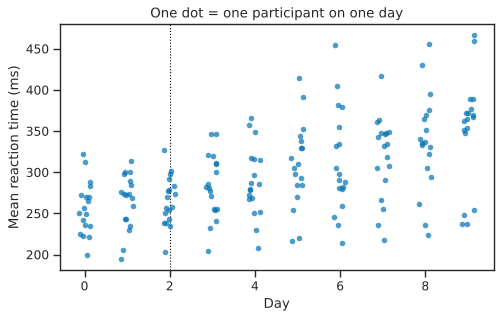

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
# Each dot is one participant's mean RT on one day.
sns.stripplot(data=sleep_df, x="Days", y="Reaction", native_scale=True,
              jitter=0.15, alpha=0.7, color="#0072B2", ax=ax)
# Mark the baseline day and the start of sleep restriction.
ax.axvline(2, color="black", linestyle=":", linewidth=1)
ax.set(xlabel="Day", ylabel="Mean reaction time (ms)",
       title="One dot = one participant on one day")
plt.show()

**Example interpretation:** Typical reaction times rise from about 250–270 ms in the first days to about 350 ms
by day 9. The spread between people also grows: on days 0–2 people range from about 200 to 330 ms; by day 9
they range from about 240 to 470 ms. Some people seem badly affected by sleep loss and others hardly at all,
but this plot can't tell us *which* dots belong to the same person.

## 3. Join each person's dots

This is a within-participant design: the same 18 people were tested every day. Use `sns.lineplot()` with
`units="Subject"` and `estimator=None` to draw **one line per participant** (in a light grey).
Then add the group mean on top with a second `lineplot` (no `units`) in a strong colour, with `errorbar=("ci", 95)`.

In the title or a comment, state what the thin lines and the thick line represent.

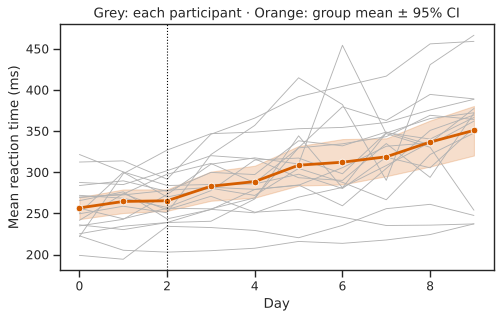

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
# Thin grey lines: one line per participant (no averaging).
sns.lineplot(data=sleep_df, x="Days", y="Reaction", units="Subject", estimator=None,
             color="0.7", linewidth=0.8, ax=ax)
# Thick line: the mean of the 18 participants on each day, with a 95% CI band.
sns.lineplot(data=sleep_df, x="Days", y="Reaction", errorbar=("ci", 95),
             color="#D55E00", linewidth=2.5, marker="o", ax=ax)
ax.axvline(2, color="black", linestyle=":", linewidth=1)
ax.set(xlabel="Day", ylabel="Mean reaction time (ms)",
       title="Grey: each participant · Orange: group mean ± 95% CI")
plt.show()

**Example interpretation:** Most lines rise after day 2, but not all at the same rate. A few climb steeply (one
person reaches about 465 ms by day 9) while a few stay almost flat. The group mean rises steadily from about 265 ms on day 2
to about 350 ms on day 9. The CI band is much narrower than the spread of the grey lines, because it
describes how precisely we know the *mean*, not how much people vary.

## 4. Small multiples: one panel per person

With 18 lines on one graph, it's hard to follow any one person. Use `sns.relplot()` with `kind="line"`,
`col="Subject"` and `col_wrap=6` to give each participant their own small panel. Add `marker="o"`.
Make the panels small (`height=1.8`) and use `g.set_titles("{col_name}")` for short titles.

Bonus: draw a dotted vertical line at day 2 in every panel with `g.refline(x=2, ...)` (see the `catplot` reference in the lecture notebook).

Questions: Does everyone slow down? Are the panels on the same y-axis, and why does that matter here?

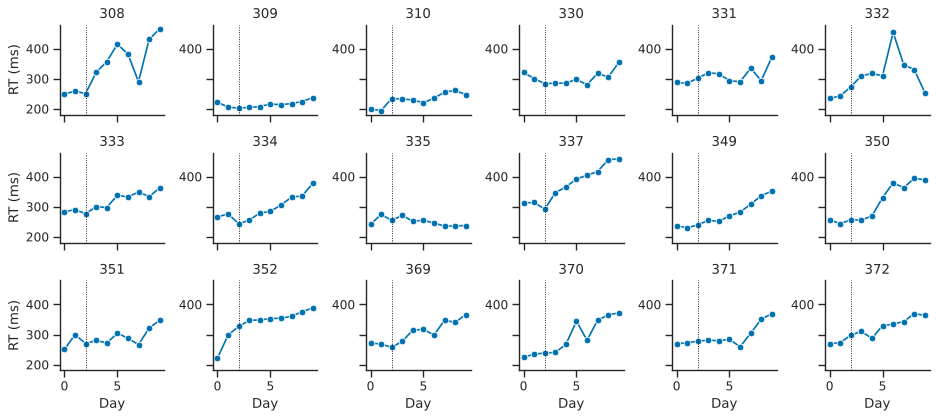

In [5]:
# relplot is figure-level: it builds the whole grid of panels and returns a FacetGrid.
g = sns.relplot(data=sleep_df, x="Days", y="Reaction", col="Subject", col_wrap=6,
                kind="line", marker="o", height=1.8, aspect=1.1, color="#0072B2")
g.set_titles("{col_name}")
g.set_axis_labels("Day", "RT (ms)")
# Mark the baseline day in every panel.
g.refline(x=2, color="black", linestyle=":", linewidth=0.8)
plt.show()

**Example interpretation:** Most participants slow down over the restriction period, but by very different
amounts: some (for example 308 and 337) rise steeply, while others (for example 309 and 335) hardly change. Participant 332 shows how noisy a single day can be: slower for
most of the week, then back near baseline on day 9. The panels share one
y-axis (the `relplot` default), so the size of each person's change can be compared directly. With separate
y-axes, a 20 ms wobble would look as dramatic as a 150 ms rise.

## 5. One point = one participant's change

Calculate each participant's **change from baseline**: Reaction on day 9 minus Reaction on day 2.

1. As in step 3 of the lecture, make a column `day2_rt` that holds `Reaction` only on the day-2 rows, and a column
   `day9_rt` that holds it only on the day-9 rows (all other rows are left as NaN).
2. Use `groupby("Subject", as_index=False).agg(...)` to get one row per participant with their day 2 and day 9
   values. Call the result `change_df`.
3. Create a column `change_ms` = day 9 − day 2.
4. Plot one dot per participant with `stripplot`, add the mean and 95% CI with `pointplot`, and draw a dashed line at 0.
5. Count how many participants got slower.

(If you tried `pivot()` from the lecture, you may use it instead.)

16 of 18 participants were slower on day 9 than on day 2


count     18.0
mean      85.5
std       60.7
min      -19.1
25%       62.9
50%       81.5
75%      127.8
max      215.6
Name: change_ms, dtype: float64

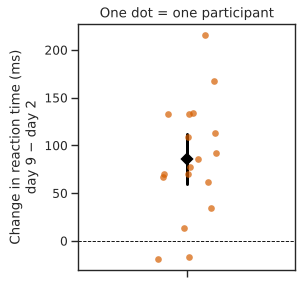

In [6]:
# Step 1: copy the data, then fill new columns only on the rows for day 2 and day 9 (other rows stay NaN).
change_calc_df = sleep_df.copy()
is_day2 = change_calc_df["Days"] == 2
is_day9 = change_calc_df["Days"] == 9
change_calc_df.loc[is_day2, "day2_rt"] = change_calc_df.loc[is_day2, "Reaction"]
change_calc_df.loc[is_day9, "day9_rt"] = change_calc_df.loc[is_day9, "Reaction"]

# Step 2: one row per participant; "mean" skips the NaNs, leaving each person's single value.
change_df = (
    change_calc_df
    .groupby("Subject", as_index=False)
    .agg(day2_rt=("day2_rt", "mean"), day9_rt=("day9_rt", "mean"))
)
# Step 3: change from baseline (day 2) to the last day (day 9).
change_df["change_ms"] = change_df["day9_rt"] - change_df["day2_rt"]

# The same with pivot (an alternative tool, not covered in class):
# sleep_wide_df = sleep_df.pivot(index="Subject", columns="Days", values="Reaction")
# sleep_wide_df["change_ms"] = sleep_wide_df[9] - sleep_wide_df[2]
# change_df = sleep_wide_df.reset_index()

fig, ax = plt.subplots(figsize=(3.5, 4))
sns.stripplot(data=change_df, y="change_ms", color="#D55E00", alpha=0.7, size=6, jitter=0.15, ax=ax)
sns.pointplot(data=change_df, y="change_ms", errorbar=("ci", 95), color="black", markers="D", ax=ax)
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set(ylabel="Change in reaction time (ms)\nday 9 − day 2", title="One dot = one participant")
plt.show()

n_slower = (change_df["change_ms"] > 0).sum()
print(f"{n_slower} of {len(change_df)} participants were slower on day 9 than on day 2")
change_df["change_ms"].describe().round(1)

**Example interpretation:** 16 of the 18 participants were slower on day 9 than at baseline. The average slowing is
about 86 ms, and the 95% CI is well above zero. But people vary a lot: changes range from about −20 ms
(slightly *faster*) to over 200 ms. A bar chart of the two daily means would have hidden both the two people with
negative changes and the person who slowed by more than 200 ms. (The small multiples in Q4 show that one of
those two, participant 332, was slower for most of the week; a change score built from a single day is noisy.)

## 6. Which error bar?

Make a figure with **three panels side by side** (`plt.subplots(1, 3, sharey=True)`). In each panel, plot the
mean Reaction for each day with `sns.pointplot()`, using `errorbar="sd"`, `errorbar="se"` and `errorbar=("ci", 95)`.
Give each panel a title naming its error bar.

Then answer: which would you choose to show **(a)** how much individuals differ on each day, and **(b)** how
precisely the study estimates the average on each day? Why do the SD bars grow over days?

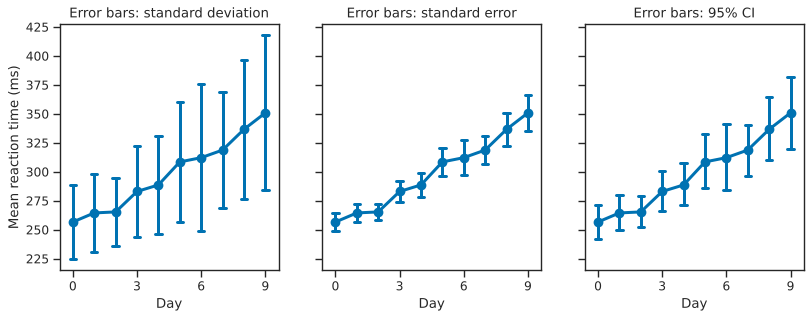

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

# The same plot three times; only errorbar= and the title change.
# native_scale=True keeps Days as numbers on the x-axis.
sns.pointplot(data=sleep_df, x="Days", y="Reaction", errorbar="sd", capsize=0.3,
              native_scale=True, color="#0072B2", ax=axes[0])
axes[0].set(title="Error bars: standard deviation", xlabel="Day", ylabel="Mean reaction time (ms)",
            xticks=range(0, 10, 3))

sns.pointplot(data=sleep_df, x="Days", y="Reaction", errorbar="se", capsize=0.3,
              native_scale=True, color="#0072B2", ax=axes[1])
axes[1].set(title="Error bars: standard error", xlabel="Day", xticks=range(0, 10, 3))

sns.pointplot(data=sleep_df, x="Days", y="Reaction", errorbar=("ci", 95), capsize=0.3,
              native_scale=True, color="#0072B2", ax=axes[2])
axes[2].set(title="Error bars: 95% CI", xlabel="Day", xticks=range(0, 10, 3))

plt.show()

**Example interpretation:** (a) The **SD** shows how much individuals differ; it grows from about 30 ms to about
65 ms because people respond to sleep loss differently (we saw this in Q4). (b) The **SE** or **95% CI**
shows how precisely we know the mean. With only 18 people, the CI is about twice as wide as the SE. Because the three
panels look so different, a legend must always say which error bar is shown.

## 7. Chart crime scene

A (fictional) poster shows the figure made by the cell below. Run it, then list **at least four problems**,
thinking about what one bar represents and what a reader can and can't learn. Then make a better figure that
answers the same question: *did reaction times get slower after a week of sleep restriction?*

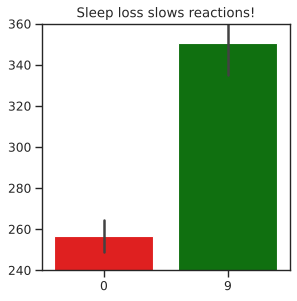

In [8]:
# Supplied code: run this and critique the figure. Do not edit it.
crime_df = sleep_df.loc[sleep_df["Days"].isin([0, 9])].copy()
crime_df["Day"] = crime_df["Days"].astype(str)

fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(data=crime_df, x="Day", y="Reaction", hue="Day", palette=["red", "green"],
            errorbar="se", legend=False, ax=ax)
ax.set_ylim(240, 360)
ax.set(xlabel="", ylabel="", title="Sleep loss slows reactions!")
plt.show()

**Example interpretation:** Problems include:
1. **The y-axis doesn't start at zero**, but bar length is meant to show the amount, so the difference looks far bigger than it is.
2. **No axis labels or units.** Is "Day" days of restriction? What is plotted on y, and in what units?
3. **Unstated error bars.** They're SE, but the reader can't know that.
4. **Bars hide the people and the pairing.** We can't see n = 18, that the same people are in both bars, or how much people differ.
5. **The wrong baseline.** Day 0 was a training day; day 2 was the baseline.
6. **Red/green** is the colour pair most often confused by colour-blind readers, and the colours carry no information anyway.

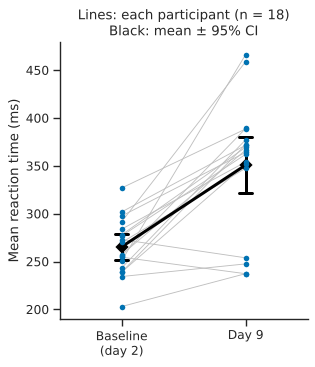

In [9]:
# A better version: paired dots for baseline (day 2) and day 9, with the mean ± 95% CI.
better_df = sleep_df.loc[sleep_df["Days"].isin([2, 9])].copy()
better_df["Day"] = better_df["Days"].map({2: "Baseline\n(day 2)", 9: "Day 9"})

fig, ax = plt.subplots(figsize=(4, 4.5))
# One grey line per participant joins their two days.
sns.lineplot(data=better_df, x="Day", y="Reaction", units="Subject", estimator=None,
             color="0.75", linewidth=0.8, ax=ax)
sns.stripplot(data=better_df, x="Day", y="Reaction", jitter=False, color="#0072B2", size=5, ax=ax)
# Group mean ± 95% CI on top.
sns.pointplot(data=better_df, x="Day", y="Reaction", errorbar=("ci", 95), color="black",
              markers="D", capsize=0.1, ax=ax)
ax.set(xlabel="", ylabel="Mean reaction time (ms)",
       title="Lines: each participant (n = 18)\nBlack: mean ± 95% CI")
sns.despine()
plt.show()

## 8. Your paper figure

Build a two-panel figure for a paper with `plt.subplot_mosaic("AB", ...)`:

- **A**: every participant's line across all days (grey), plus the group mean ± 95% CI (from Q3)
- **B**: each participant's change from baseline, with the mean ± 95% CI (from Q5)

Requirements: `sns.set_context("paper")`; a figure size of 180 mm × 70 mm (divide mm by 25.4 to get inches);
`width_ratios=[2.5, 1]`; bold panel letters; `sns.despine()`; and save it to `figures/sleep_figure.pdf`.
Remember to set the context back to `"notebook"` at the end.

Then **write a figure legend** (in the markdown cell below) that says what one mark represents, n, and what the
error bars or bands are.

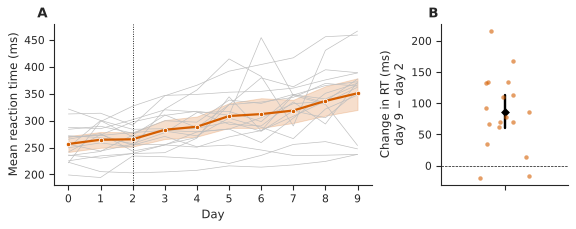

In [10]:
sns.set_context("paper", font_scale=1.1)
mm = 1 / 25.4

fig, axd = plt.subplot_mosaic("AB", figsize=(180 * mm, 70 * mm),
                              width_ratios=[2.5, 1], layout="constrained")

# --- A: individual lines + group mean -------------------------------------------
sns.lineplot(data=sleep_df, x="Days", y="Reaction", units="Subject", estimator=None,
             color="0.75", linewidth=0.6, ax=axd["A"])
sns.lineplot(data=sleep_df, x="Days", y="Reaction", errorbar=("ci", 95),
             color="#D55E00", linewidth=2, marker="o", markersize=4, ax=axd["A"])
axd["A"].axvline(2, color="black", linestyle=":", linewidth=0.8)
axd["A"].set(xlabel="Day", ylabel="Mean reaction time (ms)", xticks=range(10))

# --- B: change from baseline ------------------------------------------------------
sns.stripplot(data=change_df, y="change_ms", color="#D55E00", alpha=0.6, size=4, jitter=0.2, ax=axd["B"])
sns.pointplot(data=change_df, y="change_ms", errorbar=("ci", 95), color="black",
              markers="D", markersize=4, ax=axd["B"])
axd["B"].axhline(0, color="black", linestyle="--", linewidth=0.6)
axd["B"].set(ylabel="Change in RT (ms)\nday 9 − day 2")

sns.despine(fig=fig)
axd["A"].text(-0.02, 1.02, "A", transform=axd["A"].transAxes, fontsize=12, fontweight="bold", ha="right", va="bottom")
axd["B"].text(-0.02, 1.02, "B", transform=axd["B"].transAxes, fontsize=12, fontweight="bold", ha="right", va="bottom")

fig.savefig("figures/sleep_figure.pdf", bbox_inches="tight")
plt.show()
sns.set_context("notebook")

**Example interpretation:** **Figure 2. Reaction times slow with repeated sleep restriction.** **(A)** Mean reaction time on each
day for each participant (grey lines; n = 18) and the group mean (orange) with its 95% confidence interval
(band). The dotted line marks the baseline day (day 2); participants spent 3 h in bed per night from then on.
**(B)** Change in each participant's mean reaction time from baseline to day 9 (dots); the black diamond and bar
show the mean change and its 95% CI. The dashed line marks no change. Data from Belenky et al. (2003).

## Stretch goal: the same ladder for accuracy

Go back to the lecture's flanker data (`data/flanker_hedge2018.csv`). Accuracy (`correct`) is 1 or 0 on each trial, so
one trial on its own tells you very little. Calculate each participant's **proportion correct** in each condition
(this time use *all* trials, not just correct ones), then make the "one line per participant" plot for accuracy.
Do all participants make more errors on incongruent trials? How does the picture compare with reaction time?

46 of 47 participants were less accurate on incongruent trials


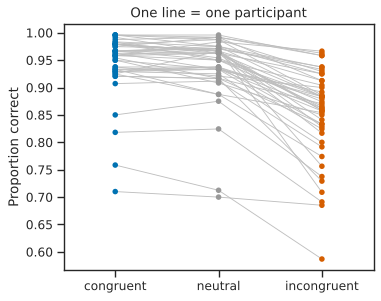

In [11]:
flanker_df = pd.read_csv("data/flanker_hedge2018.csv")
flanker_df["condition"] = pd.Categorical(flanker_df["condition"],
                                         categories=["congruent", "neutral", "incongruent"], ordered=True)

# The mean of a 0/1 column is the proportion of 1s, i.e. proportion correct.
accuracy_df = (flanker_df.groupby(["participant", "condition"], as_index=False, observed=True)
               .agg(prop_correct=("correct", "mean")))

fig, ax = plt.subplots(figsize=(5, 4))
sns.lineplot(data=accuracy_df, x="condition", y="prop_correct", units="participant",
             estimator=None, color="0.75", linewidth=0.8, ax=ax)
sns.stripplot(data=accuracy_df, x="condition", y="prop_correct", hue="condition", dodge=False,
              palette={"congruent": "#0072B2", "neutral": "#999999", "incongruent": "#D55E00"},
              jitter=False, size=5, ax=ax)
ax.set(xlabel="", ylabel="Proportion correct", title="One line = one participant")
plt.show()

# Put each person's congruent and incongruent accuracy on one row (same method as Q5).
acc_calc_df = accuracy_df.copy()
is_congruent = acc_calc_df["condition"] == "congruent"
is_incongruent = acc_calc_df["condition"] == "incongruent"
acc_calc_df.loc[is_congruent, "congruent"] = acc_calc_df.loc[is_congruent, "prop_correct"]
acc_calc_df.loc[is_incongruent, "incongruent"] = acc_calc_df.loc[is_incongruent, "prop_correct"]
acc_by_person_df = (acc_calc_df.groupby("participant", as_index=False)
                    .agg(congruent=("congruent", "mean"), incongruent=("incongruent", "mean")))

n_worse = (acc_by_person_df["incongruent"] < acc_by_person_df["congruent"]).sum()
print(f"{n_worse} of {len(acc_by_person_df)} participants were less accurate on incongruent trials")

**Example interpretation:** Almost every participant is less accurate on incongruent trials (46 of 47), so the flanker
effect shows up in accuracy too. Unlike RT, accuracy is close to the ceiling of 1.0 for many people in the
congruent and neutral conditions, so the lines bunch together at the top, and a few people with low accuracy
stand out. When plotting proportions, think about the ceiling.

### References

- Belenky, G., Wesensten, N. J., Thorne, D. R., Thomas, M. L., Sing, H. C., Redmond, D. P., Russo, M. B., & Balkin, T. J. (2003). Patterns of performance degradation and restoration during sleep restriction and subsequent recovery: a sleep dose-response study. *Journal of Sleep Research, 12*, 1–12.
- Hedge, C., Powell, G., & Sumner, P. (2018). The reliability paradox: Why robust cognitive tasks do not produce reliable individual differences. *Behavior Research Methods, 50*, 1166–1186.